# Лабораторна робота №2

**Виконав(ла): Любімова єлизавета**  
**Група: 4-9**

### Тема

Обробка та аналіз даних про ВВП країн за допомогою Python і Pandas.
---

---

## Завдання 1. Завантажити датасет і показати перші п’ять рядків



In [1]:
import pandas as pd

import numpy as np

import requests

from io import StringIO

import matplotlib.pyplot as plt

import plotly.express as px

url = 'https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)'

html = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}, timeout=30)

html.raise_for_status()

found = pd.read_html(StringIO(html.text))

for candidate in found:
    names = str(candidate.columns)
    if all(name in names for name in ['IMF', 'World Bank', 'United Nations']):
        df = candidate.copy()
        break
else:
    raise ValueError('Потрібна таблиця відсутня')

display(df.iloc[:5])


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


---

## Завдання 2. Розмір датасету



In [2]:
print("Форма таблиці (рядки, стовпці):", df.shape)


Форма таблиці (рядки, стовпці): (222, 4)


---

## Завдання 3. Вибрати потрібні стовпці



In [3]:
keep = ['Country', 'IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']

df = df.iloc[:, :len(keep)].copy()

df.columns = keep

df['Country'] = df['Country'].astype(str).str.replace(r'\[.*?\]', '', regex=True).str.strip()

df = df[~df.Country.isin(['World', 'European Union'])].copy().reset_index(drop=True)

indicators = keep[1:]

display(df.head())


,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,United States,32383920,30769700,29298000
1,China,20851593,19498039,18743802
2,Germany,5452858,5050923,4659929
3,Japan,4379253,4435163,4026211
4,United Kingdom,4264794,4002588,3685881


---

## Завдання 4. Замінити «—» на NaN, перевірити та заповнити пропуски



In [4]:
df.replace(['—', '–', '-', ''], np.nan, inplace=True)

df[indicators] = df[indicators].apply(lambda s: pd.to_numeric(s.astype(str).str.replace(',', '', regex=False).str.replace(' ', '', regex=False), errors='coerce'))

missing = df[indicators].isna().sum()

print('Пропуски за стовпцями:')

print(missing)

original = df.copy()

df[indicators] = df[indicators].fillna(df[indicators].mean())

assert df[indicators].notna().all().all(), 'Залишилися пропуски'

print('Усі пропуски заповнено середніми значеннями')


Пропуски за стовпцями:
IMF (2026)               31
World Bank (2025)        35
United Nations (2024)     9
dtype: int64
Усі пропуски заповнено середніми значеннями


---

## Завдання 5. Вивести очищений датасет



In [5]:
display(df.head(25))

print("Усього записів:", len(df))


,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,United States,32383920.0,3.076970e+07,2.929800e+07
1,China,20851593.0,1.949804e+07,1.874380e+07
2,Germany,5452858.0,5.050923e+06,4.659929e+06
3,Japan,4379253.0,4.435163e+06,4.026211e+06
4,United Kingdom,4264794.0,4.002588e+06,3.685881e+06
5,India,4153191.0,3.956067e+06,3.952244e+06
6,France,3596094.0,3.366316e+06,3.160443e+06
7,Italy,2738164.0,2.551557e+06,2.380825e+06
8,Russia,2656452.0,2.561310e+06,2.173386e+06
9,Brazil,2635912.0,2.279920e+06,2.185822e+06


Усього записів: 221


---

## Завдання 6. Перевірити і прибрати дублікати



In [6]:
n_duplicates = int(df.duplicated().sum())

print(f'Знайдено {n_duplicates} дублікатів')

df = df.loc[~df.duplicated()].reset_index(drop=True)

original = original.drop_duplicates().reset_index(drop=True)

print('Контрольна перевірка:', df.duplicated().sum())


Знайдено 0 дублікатів
Контрольна перевірка: 0


---

## Завдання 7. Описова статистика



In [7]:
summary = df[indicators].describe().T

display(summary.round(2))


,count,mean,std,min,25%,50%,75%,max
IMF (2026),221.0,661460.29,2666759.25,65.0,18959.0,102042.0,661460.29,32383920.0
World Bank (2025),221.0,626049.69,2520399.39,57.0,19928.0,99774.0,626049.69,30769700.0
United Nations (2024),221.0,522491.21,2410079.31,56.0,8840.0,42765.0,298697.00,29298000.0


---

## Завдання 8. Різниця між IMF (2026) і World Bank (2025)



In [8]:
valid = original.dropna(subset=indicators).copy()

valid['Різниця'] = valid['IMF (2026)'] - valid['World Bank (2025)']

valid['Абсолютна різниця'] = valid['Різниця'].abs()

display(valid.nlargest(8, 'Абсолютна різниця')[['Country', 'Різниця', 'Абсолютна різниця']])

largest = valid.loc[valid['Абсолютна різниця'].idxmax()]

print(f"Максимальне відхилення: {largest['Country']} ({largest['Абсолютна різниця']:,.0f} млн дол.)")


,Country,Різниця,Абсолютна різниця
0,United States,1614220.0,1614220.0
1,China,1353554.0,1353554.0
2,Germany,401935.0,401935.0
9,Brazil,355992.0,355992.0
11,Australia,325444.0,325444.0
12,Mexico,288214.0,288214.0
4,United Kingdom,262206.0,262206.0
6,France,229778.0,229778.0


Максимальне відхилення: United States (1,614,220 млн дол.)


---

## Завдання 9. Кореляція між трьома показниками



In [9]:
corr_matrix = valid[indicators].corr()

display(corr_matrix.style.background_gradient(cmap='YlGn').format('{:.4f}'))

relations = corr_matrix.where(np.triu(np.ones((3,3)), k=1).astype(bool)).stack()

print('Пара з найвищою кореляцією:', relations.idxmax())

print('Значення:', round(relations.max(), 4))


,IMF (2026),World Bank (2025),United Nations (2024)
IMF (2026),1.0000,0.9999,0.9998
World Bank (2025),0.9999,1.0000,0.9999
United Nations (2024),0.9998,0.9999,1.0000


Пара з найвищою кореляцією: ('IMF (2026)', 'World Bank (2025)')
Значення: 0.9999


---

## Завдання 10. Середні значення за стовпцями



Середній ВВП за показниками:


,0
IMF (2026),661460.29
World Bank (2025),626049.69
United Nations (2024),522491.21


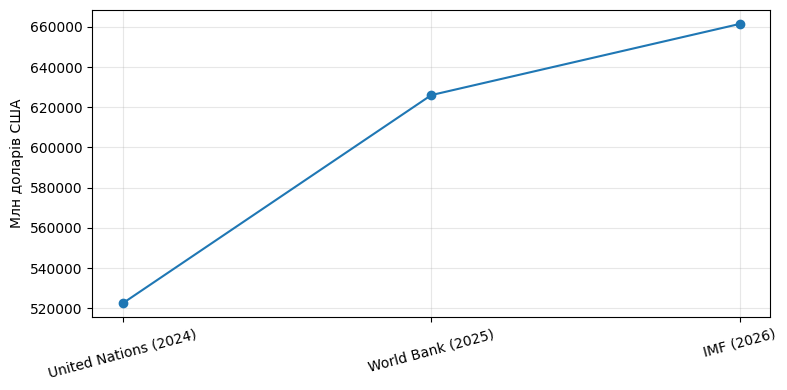

In [10]:
avg = df[indicators].mean().round(2)

print('Середній ВВП за показниками:')

display(avg)

plt.figure(figsize=(8,4))

plt.plot(indicators[::-1], avg.loc[indicators[::-1]], marker='o')

plt.ylabel('Млн доларів США')

plt.xticks(rotation=15)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


---

## Завдання 11. Стандартне відхилення по країнах



In [11]:
valid['Стандартне відхилення'] = valid[indicators].apply(lambda row: row.std(), axis=1)

leaders_std = valid.nlargest(10, 'Стандартне відхилення')

display(leaders_std[['Country','Стандартне відхилення']])

print('Найбільша варіативність у:', leaders_std.iloc[0]['Country'])


,Country,Стандартне відхилення
0,United States,1.543508e+06
1,China,1.068002e+06
2,Germany,3.964771e+05
4,United Kingdom,2.898838e+05
8,Russia,2.558938e+05
9,Brazil,2.374046e+05
3,Japan,2.217380e+05
6,France,2.179348e+05
13,Spain,1.842383e+05
11,Australia,1.793505e+05


Найбільша варіативність у: United States


---

## Завдання 12. Максимум та мінімум кожного показника



In [12]:
extremes = []

for col in indicators:
    existing = original.dropna(subset=[col])
    extremes.append({'Показник': col, 'Максимум': existing.loc[existing[col].idxmax(), 'Country'], 'Мінімум': existing.loc[existing[col].idxmin(), 'Country']})

display(pd.DataFrame(extremes))


,Показник,Максимум,Мінімум
0,IMF (2026),United States,Tuvalu
1,World Bank (2025),United States,Tuvalu
2,United Nations (2024),United States,Tuvalu


---

## Завдання 13. Гістограма IMF (2026) та особливості розподілу



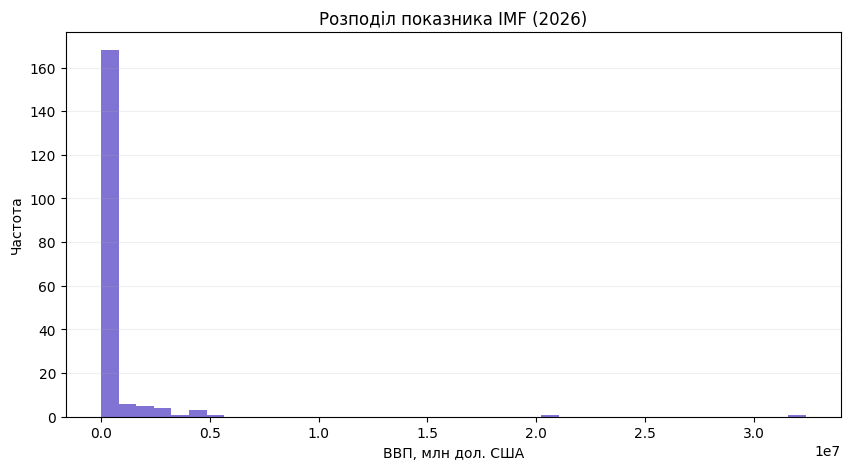

,Country,IMF (2026)
0,United States,32383920.0
1,China,20851593.0
2,Germany,5452858.0
3,Japan,4379253.0
4,United Kingdom,4264794.0


Спостерігається правостороння асиметрія: небагато великих економік мають дуже високий ВВП.


In [13]:
plt.figure(figsize=(10,5))

plt.hist(original['IMF (2026)'].dropna(), bins=40, color='slateblue', alpha=0.85)

plt.xlabel('ВВП, млн дол. США')

plt.ylabel('Частота')

plt.title('Розподіл показника IMF (2026)')

plt.grid(axis='y', alpha=.2)

plt.show()

top = original.nlargest(5, 'IMF (2026)')[['Country','IMF (2026)']]

display(top)

print('Спостерігається правостороння асиметрія: небагато великих економік мають дуже високий ВВП.')


---

## Завдання 14. Частка кожної країни в сукупному ВВП



,Country,"IMF (2026), %","World Bank (2025), %","United Nations (2024), %"
0,United States,25.767,26.424,26.450
1,China,16.591,16.744,16.922
2,Germany,4.339,4.338,4.207
3,Japan,3.485,3.809,3.635
4,United Kingdom,3.393,3.437,3.328
...,...,...,...,...
216,Palau,0.000,0.000,0.000
217,Marshall Islands,0.000,0.000,0.000
218,Nauru,0.000,0.000,0.000
219,Montserrat,NaN,NaN,0.000


Найбільше зростання часток:


,Country,delta
8,Russia,0.151602
2,Germany,0.131850
9,Brazil,0.124032
15,Turkey,0.110488
13,Spain,0.108687


Найбільше зменшення часток:


,Country,delta
0,United States,-0.682359
1,China,-0.330300
5,India,-0.263390
52,Iran,-0.165592
14,South Korea,-0.156596


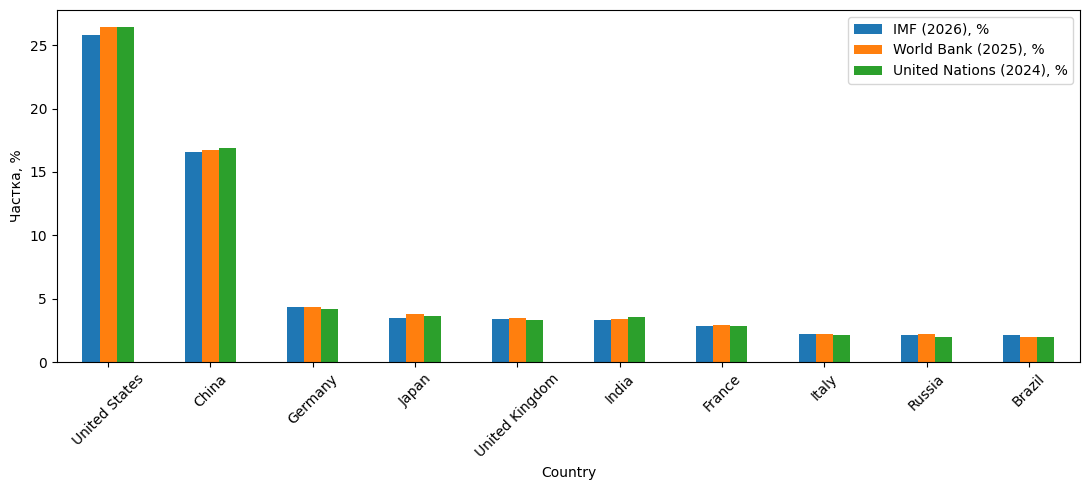

In [14]:
parts = original[['Country']].copy()

for year in indicators:
    parts[year + ', %'] = (original[year] / original[year].sum() * 100)

pct_cols = [x + ', %' for x in indicators]

display(parts[['Country'] + pct_cols].round(3))

parts['delta'] = parts['IMF (2026), %'] - parts['United Nations (2024), %']

print('Найбільше зростання часток:')

display(parts.nlargest(5,'delta')[['Country','delta']])

print('Найбільше зменшення часток:')

display(parts.nsmallest(5,'delta')[['Country','delta']])

subset = parts.nlargest(10, 'IMF (2026), %')

subset.set_index('Country')[pct_cols].plot(kind='bar', figsize=(11,5))

plt.ylabel('Частка, %')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


---

## Завдання 15. Динаміка показників за 2024–2026 роки



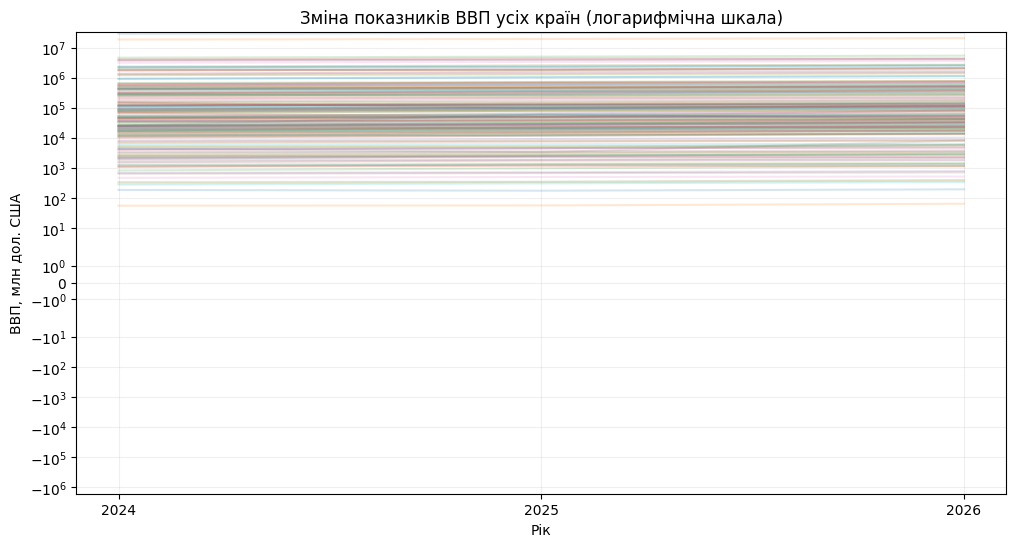

Стабільне зростання: 156 країн; приклади: ['United States', 'China', 'Germany', 'United Kingdom', 'India', 'France', 'Italy', 'Russia', 'Brazil', 'Canada']
Стабільне зниження: 2 країн; приклади: ['Iran', 'Ethiopia']


In [15]:
sequence = ['United Nations (2024)', 'World Bank (2025)', 'IMF (2026)']

complete = original.dropna(subset=sequence).copy()
# Лінії усіх країн з прозорістю для зручнішого огляду

plt.figure(figsize=(12,6))

for _, record in complete.iterrows():
    plt.plot([2024,2025,2026], record[sequence].astype(float).values, alpha=0.18)

plt.xticks([2024,2025,2026])

plt.yscale('symlog')

plt.title('Зміна показників ВВП усіх країн (логарифмічна шкала)')

plt.xlabel('Рік')

plt.ylabel('ВВП, млн дол. США')

plt.grid(alpha=.2)

plt.show()

up = complete[(complete[sequence[0]] < complete[sequence[1]]) & (complete[sequence[1]] < complete[sequence[2]])]

down = complete[(complete[sequence[0]] > complete[sequence[1]]) & (complete[sequence[1]] > complete[sequence[2]])]

print(f'Стабільне зростання: {len(up)} країн; приклади:', up['Country'].head(10).to_list())

print(f'Стабільне зниження: {len(down)} країн; приклади:', down['Country'].head(10).to_list())
